<a href="https://colab.research.google.com/github/Guo-Tang-26/DS4420-Project/blob/main/DS4420_Project_LSTM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive

drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

data_dir = Path("/content/drive/MyDrive/charles_river_data_2026-11-18")
csv_path = data_dir / "daily_merged.csv"

df = pd.read_csv(csv_path, parse_dates=["date"])

print(df.shape)
display(df[["date", "discharge_cfs_mean"]].head())

(34805, 19)


,date,discharge_cfs_mean
0,1931-08-04,45.0
1,1931-08-05,38.0
2,1931-08-06,38.0
3,1931-08-07,42.0
4,1931-08-08,54.0


#LSTM - Charles River at Waltham

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from sklearn.preprocessing import StandardScaler
from tensorflow import keras

In [ ]:
keras.utils.set_random_seed(42)
LOOKBACK = 14
HORIZON = 3
TARGET = "discharge_cfs_mean"
FEATURES = [TARGET, "precip_in", "tmean_f"]
DATE = "date"

In [ ]:
daily = df.copy()
daily[DATE] = pd.to_datetime(daily[DATE]).dt.normalize()
daily = daily.set_index(DATE).sort_index()[FEATURES].asfreq("D")
daily = daily.apply(pd.to_numeric, errors="coerce")
train_end = daily.index[int(len(daily) * 0.70)]  # first validation date
test_start = daily.index[int(len(daily) * 0.85)]  # first test date
train = daily.loc[daily.index < train_end]

# fill missing weather using only training medians and keep missing flow as NaN.
weather = [col for col in FEATURES if col != TARGET]
inputs = daily.copy()
inputs[weather] = inputs[weather].fillna(train[weather].median())
if inputs[weather].isna().any().any():
    raise ValueError("Check weather columns for missing training data.")
scaler = StandardScaler().fit(inputs.loc[train.index])
scaled = scaler.transform(inputs).astype("float32")
flow = daily[TARGET].to_numpy(dtype="float32")
print("Validation starts", train_end.date(), "| Test starts", test_start.date())

Validation starts 1998-04-17 | Test starts 2012-08-02


In [ ]:
# each input ends the day before its first forecast and keep all labels in one split.
def make_windows(start, stop):
    X, y, origins = [], [], []
    for i in range(LOOKBACK, len(daily) - HORIZON + 1):
        dates = daily.index[i:i + HORIZON]
        if dates[0] < start or dates[-1] >= stop:
            continue
        window = scaled[i - LOOKBACK:i]
        labels = flow[i:i + HORIZON]
        if np.isfinite(window).all() and np.isfinite(labels).all():
            X.append(window)
            y.append(labels)
            origins.append(i)
    if not X:
        raise ValueError("No complete windows in this split. Check dates and missing flow.")
    return np.stack(X), np.stack(y), np.array(origins)

X_train, y_train, _ = make_windows(daily.index[0], train_end)
X_val, y_val, _ = make_windows(train_end, test_start)
X_test, y_test, origins = make_windows(test_start, daily.index[-1] + pd.Timedelta(days=1))
print(X_train.shape, y_train.shape)  # (samples, past days, features), (samples, forecast days)

(24347, 14, 3) (24347, 3)


In [ ]:
# Scale training labels so the network learns on a comparable numerical scale.
center, scale = y_train.mean(), max(float(y_train.std()), 1e-6)
model = keras.Sequential([
    keras.Input(shape=(LOOKBACK, len(FEATURES))),
    keras.layers.LSTM(32),
    keras.layers.Dense(HORIZON)
])
model.compile(optimizer="adam", loss="mse")
model.fit(
    X_train, (y_train - center) / scale,
    validation_data=(X_val, (y_val - center) / scale),
    epochs=50, batch_size=32, shuffle=False,
    callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True)]
)

Epoch 1/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 8s 9ms/step - loss: 0.2152 - val_loss: 0.1562
Epoch 2/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0950 - val_loss: 0.1330
Epoch 3/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 6s 7ms/step - loss: 0.0828 - val_loss: 0.1253
Epoch 4/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 12s 10ms/step - loss: 0.0784 - val_loss: 0.1215
Epoch 5/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0762 - val_loss: 0.1194
Epoch 6/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 8s 10ms/step - loss: 0.0749 - val_loss: 0.1182
Epoch 7/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0740 - val_loss: 0.1177
Epoch 8/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0735 - val_loss: 0.1174
Epoch 9/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 6s 8ms/step - loss: 0.0730 - val_loss: 0.1173
Epoch 10/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0727 - val_loss: 0.1173
Epoch 11/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 7s 9ms/step - loss: 0.0723 - val_loss: 0.1173
Epoch 12/50
761/761 ━━━━━━━━━━━━━━━━━━━━ 11s 10m

,Model,Days ahead,MAE (cfs),RMSE (cfs)
0,LSTM,1,26.139999,45.009998
1,LSTM,2,43.950001,75.269997
2,LSTM,3,56.700001,93.660004
3,Persistence,1,24.410000,50.080002
4,Persistence,2,42.759998,79.059998
5,Persistence,3,57.520000,98.739998


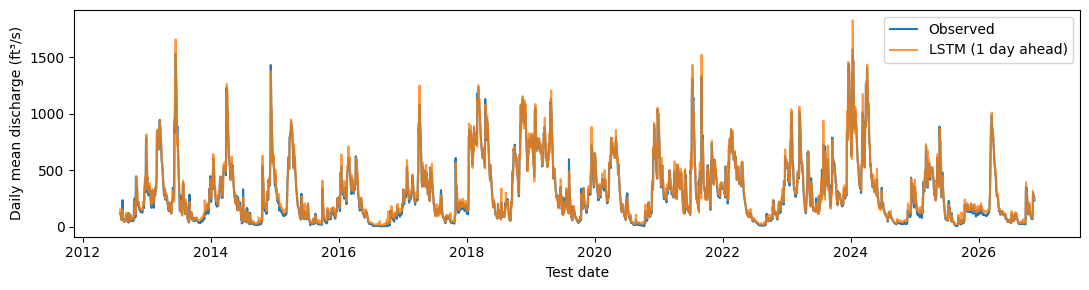

In [ ]:
pred = model.predict(X_test, verbose=0) * scale + center
# Persistence predicts the last observed flow for every future day.
baseline = np.repeat(flow[origins - 1, None], HORIZON, axis=1)
rows = []
for name, forecast in [("LSTM", pred), ("Persistence", baseline)]:
    for h in range(HORIZON):
        error = forecast[:, h] - y_test[:, h]
        rows.append([name, h + 1, np.abs(error).mean(), np.sqrt(np.mean(error**2))])
display(pd.DataFrame(rows, columns=["Model", "Days ahead", "MAE (cfs)", "RMSE (cfs)"]).round(2))

# Plot day-ahead forecasts at their target dates.
dates = daily.index[origins]
plt.figure(figsize=(11, 3))
plt.plot(dates, y_test[:, 0], label="Observed")
plt.plot(dates, pred[:, 0], label="LSTM (1 day ahead)", alpha=0.8)
plt.ylabel("Daily mean discharge (ft³/s)")
plt.xlabel("Test date")
plt.legend()
plt.tight_layout()
plt.show()